# Практическое занятие №2
## Разработка и исследование компьютерной модели для решения уравнения параболического типа. Явная схема.

## 1.1 Реализация и верификация модели


a = 0.01, dx = 0.1000, dt = 0.006667
Fo = a * dt / dx^2 = 0.0067


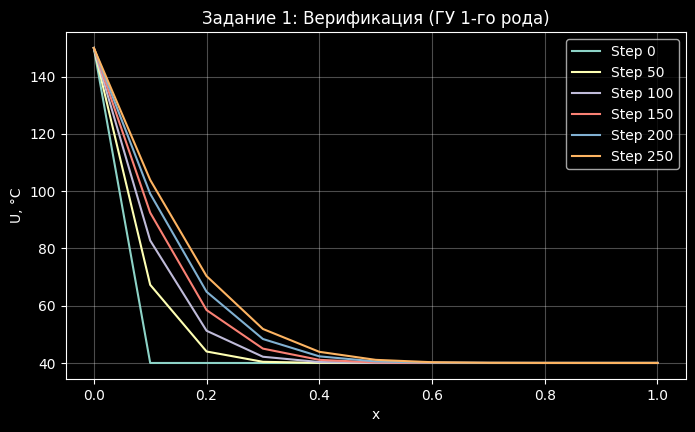

Максимальное отклонение от стационара (линейного): 6.236e+01


In [8]:
import numpy as np
import matplotlib.pyplot as plt

lam = 0.01    # коэффициент теплопроводности
c_rho = 1.0   # теплоемкость * плотность
a = lam / c_rho # коэффициент температуропроводности (a = 0.01)

Nx = 11
x = np.linspace(0, 1, Nx)
dx = x[1] - x[0]

U0 = np.full(Nx, 40.0)

t_max = 2.0
Nt = 300
dt = t_max / Nt

print(f"a = {a}, dx = {dx:.4f}, dt = {dt:.6f}")
print(f"Fo = a * dt / dx^2 = {a * dt / dx**2:.4f}")

def solve_explicit(U0, T1, T2, a, dx, dt, Nt, snapshot_every=1):
    U = U0.copy()
    history = []
    for n in range(Nt):
        U_new = U.copy()
        for i in range(1, len(U) - 1):
            U_new[i] = U[i] + a * dt / dx**2 * (U[i+1] - 2*U[i] + U[i-1])
        U_new[0] = T1
        U_new[-1] = T2
        U = U_new
        if n % snapshot_every == 0:
            history.append(U.copy())
    return history

# ГУ 1-го рода: T1=150, T2=40
T1, T2 = 150.0, 40.0

history = solve_explicit(U0, T1, T2, a, dx, dt, Nt, snapshot_every=10)

plt.figure(figsize=(8, 4.5))
for i, U_snap in enumerate(history):
    if i % 5 == 0:
        plt.plot(x, U_snap, label=f'Step {i*10}')
plt.xlabel('x'); plt.ylabel('U, °C')
plt.title('Задание 1: Верификация (ГУ 1-го рода)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

U_stationary = np.linspace(T1, T2, Nx)
U_final = history[-1]
err = np.abs(U_final - U_stationary).max()
print(f"Максимальное отклонение от стационара (линейного): {err:.3e}")

---
## 2. Проверка устойчивости реализованной модели

Fo для a=0.1: 0.067 (должно быть > 0.5)


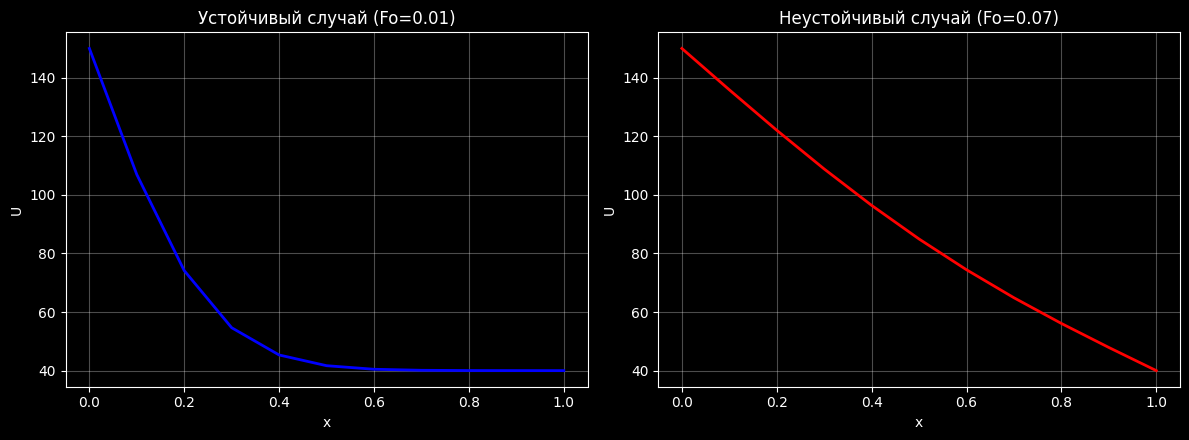

Диапазон U в неустойчивом случае: [40.0, 150.0]
→ Решение «разлетается» при Fo > 0.5 — схема неустойчива


In [9]:
# Неустойчивый случай: a в 10 раз больше
a_unstable = a * 10
Fo_unstable = a_unstable * dt / dx**2
print(f"Fo для a=0.1: {Fo_unstable:.3f} (должно быть > 0.5)")

history_unstable = solve_explicit(U0, T1, T2, a_unstable, dx, dt, Nt, snapshot_every=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(x, history[-1], 'b-', linewidth=2)
axes[0].set_title(f'Устойчивый случай (Fo={a*dt/dx**2:.2f})')
axes[0].set_xlabel('x'); axes[0].set_ylabel('U'); axes[0].grid(alpha=0.3)

axes[1].plot(x, history_unstable[-1], 'r-', linewidth=2)
axes[1].set_title(f'Неустойчивый случай (Fo={Fo_unstable:.2f})')
axes[1].set_xlabel('x'); axes[1].set_ylabel('U'); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Диапазон U в неустойчивом случае: [{history_unstable[-1].min():.1f}, {history_unstable[-1].max():.1f}]")
print("→ Решение «разлетается» при Fo > 0.5 — схема неустойчива")

---
## 3. Зависимость от временного шага

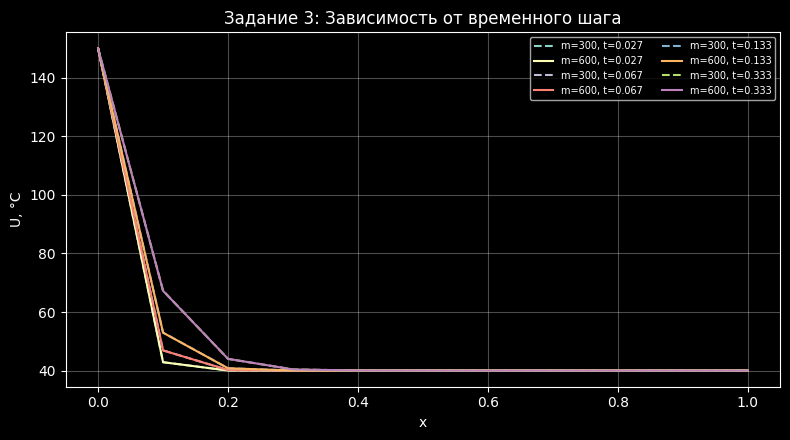

Расхождение в одинаковые моменты времени:
  t=0.027 сек: max|ΔU| = 0.0093 °C
  t=0.067 сек: max|ΔU| = 0.0210 °C
  t=0.133 сек: max|ΔU| = 0.0358 °C
  t=0.333 сек: max|ΔU| = 0.0560 °C


In [10]:
# Сравнение nt=300 и nt=600 в одинаковые моменты времени
m1, m2 = 300, 600
dt1, dt2 = t_max / m1, t_max / m2

# Для сравнения выберем 4 момента: 0.027, 0.067, 0.133, 0.333 сек
t_compare = [0.027, 0.067, 0.133, 0.333]

h1 = solve_explicit(U0, T1, T2, a, dx, dt1, m1, snapshot_every=1)
h2 = solve_explicit(U0, T1, T2, a, dx, dt2, m2, snapshot_every=1)

plt.figure(figsize=(8, 4.5))
for t in t_compare:
    idx1 = int(round(t / dt1))
    idx2 = int(round(t / dt2))
    plt.plot(x, h1[idx1], '--', label=f'm={m1}, t={t:.3f}')
    plt.plot(x, h2[idx2], '-', label=f'm={m2}, t={t:.3f}')

plt.xlabel('x'); plt.ylabel('U, °C')
plt.title('Задание 3: Зависимость от временного шага')
plt.legend(fontsize=7, ncol=2); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Расхождение в одинаковые моменты времени:")
for t in t_compare:
    idx1 = int(round(t / dt1))
    idx2 = int(round(t / dt2))
    d = np.abs(h1[idx1] - h2[idx2]).max()
    print(f"  t={t:.3f} сек: max|ΔU| = {d:.4f} °C")

---
## 4. Граничные условия третьего рода

Стационарные значения (численно): u_left=146.70, u_right=40.01
Аналитика из методички:          u_left=138.42, u_right=51.58


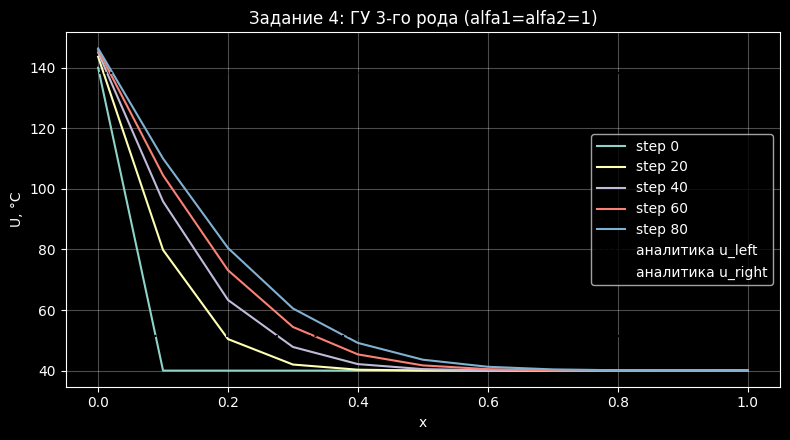

In [11]:
def solve_explicit_3(U0, U1_env, U2_env, alfa1, alfa2, lam, a, dx, dt, Nt):
    U = U0.copy()
    B1 = alfa1 * dx / lam
    B2 = alfa2 * dx / lam
    history = []
    for n in range(Nt):
        U_new = U.copy()
        for i in range(1, len(U) - 1):
            U_new[i] = U[i] + a * dt / dx**2 * (U[i+1] - 2*U[i] + U[i-1])
        U_new[0] = (U_new[1] + U1_env * B1) / (1 + B1)
        U_new[-1] = (U_new[-2] + U2_env * B2) / (1 + B2)
        U = U_new
        if n % 5 == 0:
            history.append(U.copy())
    return history

# Параметры ГУ 3-го рода
U_env_left = 150.0
U_env_right = 40.0
alfa1 = 1.0
alfa2 = 1.0

history_3 = solve_explicit_3(U0, U_env_left, U_env_right, alfa1, alfa2,
                             lam, a, dx, dt, Nt=500)

U_final_3 = history_3[-1]
print(f"Стационарные значения (численно): u_left={U_final_3[0]:.2f}, u_right={U_final_3[-1]:.2f}")
print(f"Аналитика из методички:          u_left=138.42, u_right=51.58")

plt.figure(figsize=(8, 4.5))
for i in range(0, len(history_3), len(history_3)//5):
    plt.plot(x, history_3[i], label=f'step {i}')
plt.axhline(138.42, color='k', linestyle=':', label='аналитика u_left')
plt.axhline(51.58, color='k', linestyle=':', label='аналитика u_right')
plt.xlabel('x'); plt.ylabel('U, °C')
plt.title('Задание 4: ГУ 3-го рода (alfa1=alfa2=1)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Выводы

1. **Задание 1.** Разработана явная схема для уравнения теплопроводности.
   Верификация по стационарному линейному профилю (при ГУ 1-го рода) подтвердила
   корректность модели.

2. **Задание 2.** Проверено условие устойчивости \(Fo = a\Delta t/\Delta x^2 \le 0.5\).
   При \(Fo \le 0.5\) решение гладкое; при \(Fo > 0.5\) — «разлетается»,
   схема теряет устойчивость.

3. **Задание 3.** При уменьшении \(\Delta t\) в 2 раза решение в одинаковые
   моменты времени совпадает с малой погрешностью — схема сходится.

4. **Задание 4.** Реализованы ГУ третьего рода. Стационарные значения на границах
   (\(\approx 138.42\) и \(\approx 51.58\) °C) совпадают с аналитическими из методички,
   что подтверждает корректность реализации ГУ 3-го рода.

#### Явная схема проста в реализации, но требует выполнения условия устойчивости \(Fo \le 0.5\). При его нарушении решение непригодно. Для ГУ 3-го рода модель корректно воспроизводит стационарные значения.